# 03 — Running the pipeline on lightcone slices and building analysis samples

Stage A (`RomanMockPipeline.run`) processes whole slices and writes OpenCosmo files. Stage B
(`build_samples`) applies footprint, redshift, tracer and quality cuts and can downsample to a
target dN/dz. Outputs go to `WORK` (your `$PSCRATCH`). Three slices are processed here (≈ 1–2 min);
for the whole mock use the CLI with a job array (`scripts/run_slices.sh`).

In [1]:
import os
os.environ.setdefault("JAX_PLATFORMS", "cpu")   # diffsky imports JAX; avoid CUDA probing on login nodes
import warnings
warnings.filterwarnings("ignore", message="Version checking")

import numpy as np
import matplotlib.pyplot as plt
import opencosmo as oc

from romanmock import plotting
plotting.use_style()

CATALOG = "/global/cfs/cdirs/m4943/Simulations/sdss_feniks_hizels_260710_09_07_2026"
WORK = os.path.join(os.environ.get("PSCRATCH", "/tmp"), "romanmock_demo")   # outputs of the tutorials
os.makedirs(WORK, exist_ok=True)

## Stage A: configuration and run

The configuration is a dataclass that round-trips to YAML (`cfg.to_yaml()`), so the same
object drives the CLI. Each slice gets a random stream seeded by `(seed, step)`.

In [2]:
from romanmock import RomanMockConfig, RomanMockPipeline

cfg = RomanMockConfig.from_dict({
    "catalog": {"path": CATALOG, "steps": [148, 219, 224]},   # the intended parent catalog: three slices
    "output": {"dir": os.path.join(WORK, "parent"), "overwrite": False, "store_fluxes": True,   # fluxes are optional; kept here to show them
               "passthrough_columns": ["gal_id", "ra", "dec", "redshift_true", "logsm_obs", "roman_F158"]},
    "line_set": "roman_transitions",
    "sensitivity": {"type": "constant", "flux_limit": 1e-16, "wave_range": [10000.0, 19300.0]},
    "confusion": {"type": "matrix", "default_p_fail": 0.02, "rows": {
        "Ha":        {"OIII_5007": 0.05, "OII_3727": 0.03, "fail": 0.05},
        "OIII_5007": {"Ha": 0.15, "OII_3727": 0.05, "fail": 0.05},
        "OII_3727":  {"Ha": 0.15, "OIII_5007": 0.10, "fail": 0.10}}},
    "seed": 2026,
})
pipe = RomanMockPipeline(cfg)
outputs = pipe.run()      # slices already completed with this configuration are reused (see the manifest)
outputs

[romanmock] step  148  z=[2.252,2.317]  n=6,467,954  -> lc_cores-148.romanmock.hdf5


[romanmock]     wrote 249,558 galaxies (3.86% of slice)


[romanmock] step  219  z=[1.209,1.258]  n=7,112,654  -> lc_cores-219.romanmock.hdf5


[romanmock]     wrote 2,266,451 galaxies (31.87% of slice)


[romanmock] step  224  z=[1.152,1.209]  n=8,085,039  -> lc_cores-224.romanmock.hdf5


[romanmock]     wrote 2,587,540 galaxies (32.00% of slice)


[PosixPath('/pscratch/sd/w/willlake/romanmock_demo/parent/lc_cores-148.romanmock.hdf5'),
 PosixPath('/pscratch/sd/w/willlake/romanmock_demo/parent/lc_cores-219.romanmock.hdf5'),
 PosixPath('/pscratch/sd/w/willlake/romanmock_demo/parent/lc_cores-224.romanmock.hdf5')]

Every run writes a manifest of completed slices with a hash of the scientific configuration
(line set, sensitivity, detection, confusion, seed, ...). A rerun with the same configuration
reuses finished slices; a changed configuration refuses to mix with existing outputs unless
`output.overwrite` is set, and stage B only accepts a parent catalog whose manifest matches the
configuration and covers every selected slice.

In [3]:
print(open(os.path.join(cfg.output.dir, "romanmock_manifest.yaml")).read())
print(open(os.path.join(cfg.output.dir, "romanmock_metadata.yaml")).read()[:600])

config_hash: f13feded2261a206
romanmock_version: 0.2.0
slices:
  148:
    input: lc_cores-148.diffsky_gals.hdf5
    input_size: 7270907142
    output: lc_cores-148.romanmock.hdf5
    n_galaxies: 249558
    completed: '2026-09-24T08:12:55'
  219:
    input: lc_cores-219.diffsky_gals.hdf5
    input_size: 7999133599
    output: lc_cores-219.romanmock.hdf5
    n_galaxies: 2266451
    completed: '2026-09-24T08:13:11'
  224:
    input: lc_cores-224.diffsky_gals.hdf5
    input_size: 9081578311
    output: lc_cores-224.romanmock.hdf5
    n_galaxies: 2587540
    completed: '2026-09-24T08:13:29'

created: '2026-09-24T08:12:41'
versions:
  romanmock: 0.2.0
  opencosmo: 1.3.11
  numpy: 2.5.2
  diffsky: 0.3.8
config:
  catalog:
    path: /global/cfs/cdirs/m4943/Simulations/sdss_feniks_hizels_260710_09_07_2026
    files: null
    steps:
    - 148
    - 219
    - 224
    z_min: null
    z_max: null
    open_kwargs:
      synth_cores: false
      keep_top_host: true
    rest_waves_from_catalog: true
 

## The parent emission-line catalog

The per-slice outputs re-open as one `opencosmo.Lightcone`; header, cosmology and HEALPix index
are preserved, so all OpenCosmo queries (`filter`, `cone_search`, `with_redshift_range`, ...) work.

In [4]:
parent = pipe.open_parent()
print(len(parent), "galaxies, z_range", parent.z_range)
print(parent.columns)
print(parent.units["Ha_flux"], "|", parent.descriptions["id_outcome"])

5103549 galaxies, z_range (1.1520342612419703, 2.3168316831683176)
['Ha_flux', 'Hb_flux', 'OIII_4363_flux', 'OIII_4959_flux', 'OIII_5007_flux', 'OII_3727_flux', 'SIII_6312_flux', 'SIII_9069_flux', 'SIII_9532_flux', 'dec', 'gal_id', 'id_outcome', 'line_assigned', 'line_bitmask', 'line_true', 'logsm_obs', 'n_det', 'ra', 'redshift', 'redshift_assigned', 'redshift_rsd', 'redshift_true', 'roman_F158']
erg / (s cm2) | Identification outcome: 0=NOT_DETECTED; 1=MULTI_LINE; 2=SINGLE_CORRECT; 3=SINGLE_MISID; 4=SINGLE_FAILED


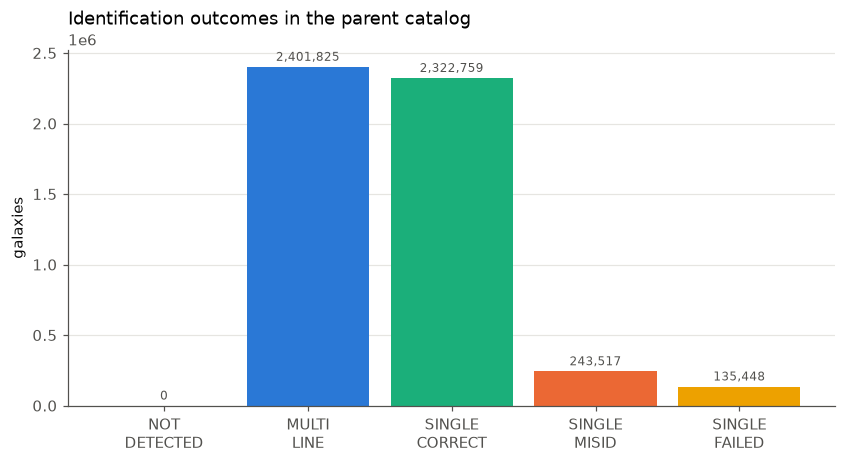

In [5]:
from romanmock.diagnostics import outcome_summary

cols = ["redshift_assigned", "redshift_rsd", "id_outcome", "n_det", "line_true", "line_assigned", "ra", "dec"]
pdata = parent.select(*cols).get_data("numpy", wrap_single=True)
summary = outcome_summary(pdata)
fig, ax = plt.subplots(figsize=(9, 4.2))
plotting.bar(ax, [k.replace("_", "\n") for k in summary], list(summary.values()), colors=[plotting.OUTCOME_COLORS[k] for k in summary])
ax.set_ylabel("galaxies"); ax.set_title("Identification outcomes in the parent catalog"); plt.show()

## dN/dz of the assigned-Hα sample and its contamination

An observer's Hα sample is every galaxy *assigned* Hα (`line_assigned == bit("Ha")`) with a
redshift. The contamination fraction `f_{i→j}(B)` uses that sample as denominator
(plan comment 4): here [O III] 5007 emitters at z ≈ 2.3 misidentified as Hα appear at assigned redshift 1.5.

Only three slices were processed, so the bins around assigned redshift 1.5 contain interlopers and no
true Hα emitters (there is no slice at z ≈ 1.5 in this demo), which is why the interloper fraction
reaches 100 % there. In a full run those bins are dominated by genuine Hα galaxies and the
fraction is a few per cent, set by the confusion matrix and the relative abundances.

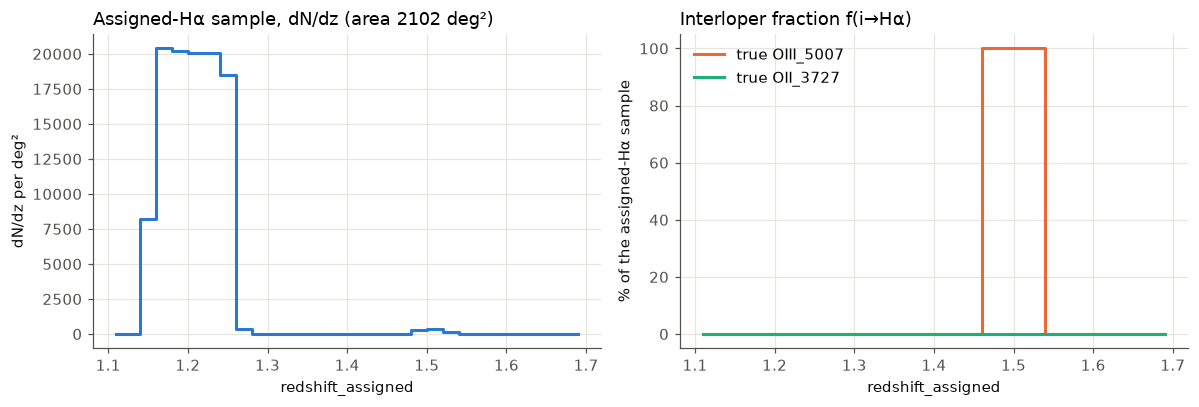

In [6]:
from romanmock.diagnostics import contamination_fraction, completeness, dndz
from romanmock.selection import sky_area_deg2

area = sky_area_deg2(parent, nside=256)
z_edges = np.linspace(1.1, 1.7, 31)
cont = contamination_fraction(pdata, pipe.line_set, z_edges, assigned_line="Ha")
zc = 0.5 * (z_edges[1:] + z_edges[:-1])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
ax1.step(zc, cont["n_sample"] / (np.diff(z_edges) * area), where="mid", color=plotting.feature_color("Ha"))
ax1.set_xlabel("redshift_assigned"); ax1.set_ylabel("dN/dz per deg²"); ax1.set_title(f"Assigned-Hα sample, dN/dz (area {area:.0f} deg²)")
for name in ["OIII_5007", "OII_3727"]:
    i = pipe.line_set.bit(name)
    ax2.step(zc, cont["fraction"][i] * 100, where="mid", color=plotting.feature_color(name), label=f"true {name}")
ax2.set_xlabel("redshift_assigned"); ax2.set_ylabel("% of the assigned-Hα sample"); ax2.set_title("Interloper fraction f(i→Hα)"); ax2.legend()
plt.tight_layout(); plt.show()

In [7]:
comp = completeness(pdata, pipe.line_set, np.linspace(1.15, 1.26, 12), line="Ha")
print("Hα completeness per true-z bin:", np.round(comp["completeness"], 3))

Hα completeness per true-z bin: [0.938 0.937 0.936 0.935 0.934 0.934 0.933 0.931 0.931 0.931 0.93 ]


## Stage B: analysis samples

A `SampleConfig` defines cuts; `downsample` thins the sample to a target dN/dz with
`p_keep = target / mock` (never above 1). The target here is a smooth curve at 40% of the mock
density, just to demonstrate the mechanics; the mock dN/dz used in the ratio is estimated inside
the footprint and smoothed over one bin.

In [8]:
from romanmock.config import SampleConfig, DownsampleConfig
from romanmock.selection import build_footprint

box = {"type": "box", "ra_min": 0.0, "ra_max": 45.0, "dec_min": 55.0, "dec_max": 66.0}
footprint = build_footprint(box)
fp_area = sky_area_deg2(parent, 256, footprint=footprint)
sel = (pdata["line_assigned"] == pipe.line_set.bit("Ha")) & np.isfinite(pdata["redshift_assigned"]) & footprint(pdata["ra"], pdata["dec"])
edges = np.linspace(1.15, 1.26, 12)
mock = dndz(pdata["redshift_assigned"][sel], edges, fp_area)
zc = 0.5 * (edges[1:] + edges[:-1])
target = {"z": zc.tolist(), "dndz": (0.4 * np.convolve(mock, np.ones(3) / 3, mode="same")).tolist()}

samples = [
    SampleConfig(name="halpha_full", z_min=1.15, z_max=1.26, assigned_lines=["Ha"]),
    SampleConfig(name="halpha_box_downsampled", z_min=1.15, z_max=1.26, assigned_lines=["Ha"], footprint=box,
                 downsample=DownsampleConfig(target=target, z_edges=edges.tolist(), smooth_bins=1.0)),
]
cfg.output.overwrite = True
sample_files = pipe.build_samples(samples=samples)
sample_files

[romanmock] sample 'halpha_full': 4,504,016 of 5,103,549 parent galaxies


[romanmock] sample 'halpha_box_downsampled': area 137.80 deg^2, p_keep range 0.279-0.407
[romanmock] sample 'halpha_box_downsampled': 110,136 of 5,103,549 parent galaxies


[PosixPath('/pscratch/sd/w/willlake/romanmock_demo/parent/samples/halpha_full.hdf5'),
 PosixPath('/pscratch/sd/w/willlake/romanmock_demo/parent/samples/halpha_box_downsampled.hdf5')]

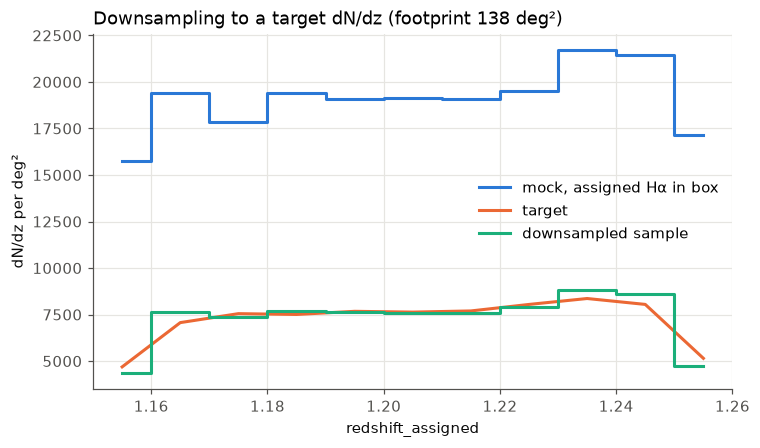

_config_hash: f13feded2261a206
created: '2026-09-24T08:13:38'
p_keep:
- 0.2794538978180357
- 0.39423543003701284
- 0.40715940057700495
- 0.39707622831014905
- 0.40201406584227356
- 0.39890769041297347
- 0.39775328318716574
- 0.4018004577261865
- 0.4038230993905651
- 0.3999711278383151
- 0.27898214532170873
z_edges:
- 1.15
- 1.16
- 1.17
- 1.18
- 1.19
- 1.2
- 1.21
- 1.22
- 1.23
- 1.24
- 1.25
- 1.26



In [9]:
ds_sample = oc.open(sample_files[1])
zs = ds_sample.select("redshift_assigned").get_data("numpy")
fig, ax = plt.subplots()
ax.step(zc, mock, where="mid", color=plotting.CATEGORICAL[0], label="mock, assigned Hα in box")
ax.plot(zc, target["dndz"], color=plotting.CATEGORICAL[1], label="target")
ax.step(zc, dndz(zs, edges, fp_area), where="mid", color=plotting.CATEGORICAL[2], label="downsampled sample")
ax.set_xlabel("redshift_assigned"); ax.set_ylabel("dN/dz per deg²"); ax.set_title(f"Downsampling to a target dN/dz (footprint {fp_area:.0f} deg²)")
ax.legend(); plt.show()
print(open(os.path.join(WORK, "parent", "samples", "halpha_box_downsampled_metadata.yaml")).read()[-400:])

The sample file keeps `ra`, `dec`, `redshift_true`, `redshift_rsd`, `redshift_assigned` and `id_outcome`
(configurable with `output.sample_columns`); the parent catalog also has `line_bitmask`, `line_true`, `line_assigned`,
so completeness, contamination and clustering can be checked against the truth, as the plan asks.